In [10]:
import os
import pandas as pd
import rasterio 
import matplotlib.pyplot as plt
from rasterio.transform import from_bounds
os.chdir ('C:\\Users\\hamod4691\\OneDrive - UiT Office 365\\Data paper code\\GEBCO')

In [1]:
# Inspect rasters

Bounds for gebco_2025_n90.0_s0.0_w0.0_e90.0.tif: BoundingBox(left=-1.8943180357666733e-15, bottom=0.0, right=89.99999999999999, top=90.0)


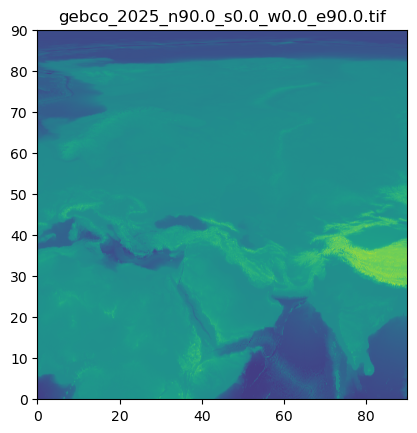

Bounds for gebco_2025_n90.0_s0.0_w-90.0_e0.0.tif: BoundingBox(left=-90.0, bottom=0.0, right=0.0, top=90.0)


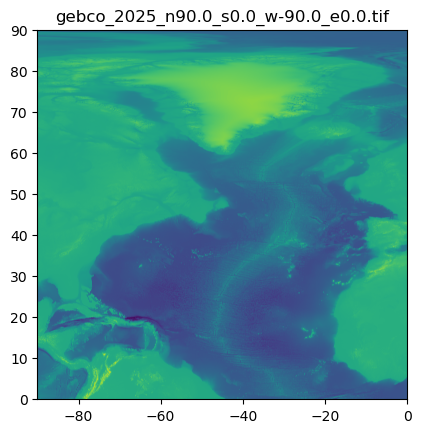

Bounds for gebco_2025_n90.0_s0.0_w90.0_e180.0.tif: BoundingBox(left=89.99999999999997, bottom=0.0, right=180.0, top=90.0)


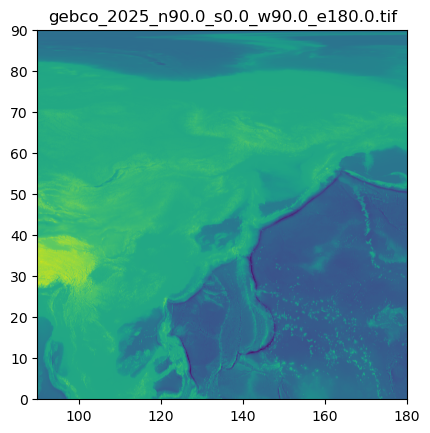

Bounds for gebco_2025_n90.0_s0.0_w-180.0_e-90.0.tif: BoundingBox(left=-180.0, bottom=0.0, right=-90.0, top=90.0)


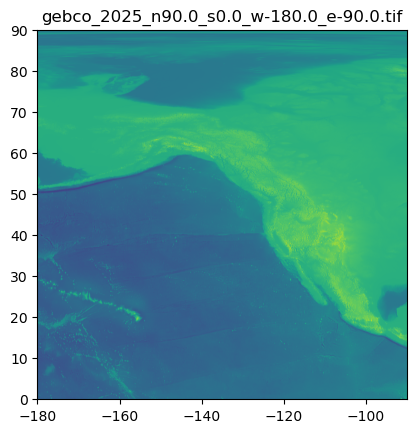

In [7]:
# List of raster file paths
raster_files = [
    "gebco_2025_n90.0_s0.0_w0.0_e90.0.tif",
    "gebco_2025_n90.0_s0.0_w-90.0_e0.0.tif",
    "gebco_2025_n90.0_s0.0_w90.0_e180.0.tif",
    "gebco_2025_n90.0_s0.0_w-180.0_e-90.0.tif",
]

# Visualize raster bounds
for raster_path in raster_files:
    with rasterio.open(raster_path) as src:
        print(f"Bounds for {raster_path}: {src.bounds}")
        plt.imshow(src.read(1), extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])
        plt.title(raster_path)
        plt.show()

In [8]:
# Fix raster bounds

In [11]:
# Function to fix raster bounds
def fix_raster_bounds(input_raster, output_raster, new_bounds):
    with rasterio.open(input_raster) as src:
        # Update the transform and bounds
        transform = from_bounds(*new_bounds, src.width, src.height)
        profile = src.profile
        profile.update({
            'transform': transform,
            'width': src.width,
            'height': src.height
        })
        # Write the fixed raster
        with rasterio.open(output_raster, 'w', **profile) as dst:
            dst.write(src.read())
# Fix the bounds of the rasters
fix_raster_bounds(
    "gebco_2025_n90.0_s0.0_w0.0_e90.0.tif",
    "fixed_gebco_2025_n90.0_s0.0_w0.0_e90.0.tif",
    new_bounds=(0, 0, 90, 90)
)
fix_raster_bounds(
    "gebco_2025_n90.0_s0.0_w90.0_e180.0.tif",
    "fixed_gebco_2025_n90.0_s0.0_w90.0_e180.0.tif",
    new_bounds=(90, 0, 180, 90)
)

In [ ]:
# Merge rasters

In [12]:
# List of input raster files
input_rasters = [
    "fixed_gebco_2025_n90.0_s0.0_w0.0_e90.0.tif",
    "gebco_2025_n90.0_s0.0_w-90.0_e0.0.tif",
    "fixed_gebco_2025_n90.0_s0.0_w90.0_e180.0.tif",
    "gebco_2025_n90.0_s0.0_w-180.0_e-90.0.tif",
]
# Output raster file
output_raster = "gebco_merged.tif"
# Merge the rasters
gdal.Warp(
    output_raster,  # Output file
    input_rasters,  # List of input rasters
    format="GTiff",  # Output format (GeoTIFF)
    options=["COMPRESS=LZW"],  # Compression option
)
print(f"Rasters merged successfully into '{output_raster}'.")

NameError: name 'gdal' is not defined